# Prakiraan Kehilangan Tutupan Pohon dan Emisi per Provinsi di Indonesia

Proyek Kelompok 6 (SDGs 15). Versi revisi: evaluasi bebas kebocoran data (*data leakage*), pembanding (*baseline*), dan emisi resmi GFW.

**Catatan definisi.** Data GFW mengukur *tree cover loss* (kehilangan tutupan pohon >5 m). Menurut Read_Me GFW, *loss* mencakup panen, kebakaran, penyakit, dan badai, termasuk di perkebunan, sehingga **tidak sama dengan deforestasi**.

**Sumber data.** Global Forest Watch, `IDN.xlsx` (sheet *Subnational 1 tree cover loss* dan *Subnational 1 carbon data*), ambang tutupan 30%. Metodologi emisi: Harris et al. (2021), *Nature Climate Change* 11: 234-240; Gibbs et al. (2025), *ESSD* 17(3): 1217-1243 (keduanya disitasi di sheet Read_Me).

**Alur.** Data → emisi resmi GFW → fitur tanpa kebocoran → baseline → tuning Optuna → evaluasi waktu (val 2021-2023, test 2024) → backtest bergulir → model final → prakiraan rekursif → CSV untuk dashboard.

In [1]:
# Di Colab: jalankan sel ini sekali (optuna belum terpasang secara bawaan)
try:
    import optuna  # noqa: F401
except ImportError:
    get_ipython().run_line_magic("pip", "install -q optuna")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 23.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 18.2 MB/s eta 0:00:00


In [2]:
import json, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import optuna
import sklearn
from sklearn.metrics import mean_squared_error, mean_absolute_error, median_absolute_error, r2_score

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

DATA_PATH = "IDN.xlsx"          # Colab: unggah IDN.xlsx ke /content
THRESHOLD = 30                  # ambang tutupan pohon standar GFW
FIRST_TARGET_YEAR = 2006        # tahun pertama dengan lag_5 lengkap
TRAIN_END, VAL_END, TEST_YEAR = 2020, 2023, 2024
FORECAST_HORIZON = 6            # 2025-2030
EMISSION_FACTOR_YEARS = (2020, 2024)
N_TRIALS = 40
SEED = 42
OUT_DATA, OUT_MODEL = "outputs/data", "outputs/model"
os.makedirs(OUT_DATA, exist_ok=True); os.makedirs(OUT_MODEL, exist_ok=True)

print("pandas", pd.__version__, "| numpy", np.__version__, "| xgboost", xgb.__version__,
      "| optuna", optuna.__version__, "| scikit-learn", sklearn.__version__)

pandas 2.2.3 | numpy 2.1.3 | xgboost 3.4.1 | optuna 5.0.0 | scikit-learn 1.6.1


## 1. Data kehilangan tutupan pohon

In [3]:
loss_raw = pd.read_excel(DATA_PATH, sheet_name="Subnational 1 tree cover loss")
loss_raw = loss_raw[loss_raw["threshold"] == THRESHOLD]
loss_cols = [c for c in loss_raw.columns if c.startswith("tc_loss_ha_")]

loss = loss_raw.melt(id_vars=["subnational1", "extent_2000_ha"], value_vars=loss_cols,
                     var_name="year", value_name="loss_ha")
loss["year"] = loss["year"].str.extract(r"(\d{4})", expand=False).astype(int)
print(loss.shape, "| provinsi:", loss["subnational1"].nunique(),
      "| tahun:", loss["year"].min(), "-", loss["year"].max())

(816, 4) | provinsi: 34 | tahun: 2001 - 2024


## 2. Emisi: kolom resmi GFW

Versi lama menghitung `loss_ha × avg_..._Mg_C_ha-1 × 3,67`. Hasilnya sekitar 2,7 kali emisi resmi GFW di file yang sama. Read_Me menyebut kepadatan itu dalam Mg biomassa/ha, bukan Mg karbon/ha. Versi ini memakai `gfw_forest_carbon_gross_emissions_{tahun}__Mg_CO2e` langsung.

In [4]:
carbon = pd.read_excel(DATA_PATH, sheet_name="Subnational 1 carbon data")
carbon = carbon[carbon["umd_tree_cover_density_2000__threshold"] == THRESHOLD]
em_cols = [c for c in carbon.columns if c.startswith("gfw_forest_carbon_gross_emissions_20")]
emis = carbon.melt(id_vars="subnational1", value_vars=em_cols,
                   var_name="year", value_name="emission_CO2e")
emis["year"] = emis["year"].str.extract(r"_(\d{4})__", expand=False).astype(int)

hist = loss.merge(emis, on=["subnational1", "year"], how="left", validate="one_to_one")
hist["loss_rate_%"] = hist["loss_ha"] / hist["extent_2000_ha"] * 100
assert hist[["loss_ha", "emission_CO2e"]].notna().all().all(), "Ada nilai kosong setelah merge"

# Perbandingan dengan rumus lama, untuk dokumentasi
dens = carbon.set_index("subnational1")["avg_gfw_aboveground_carbon_stocks_2000__Mg_C_ha-1"]
old_est = (hist["loss_ha"] * hist["subnational1"].map(dens) * 3.67).sum()
print(f"Emisi GFW 2001-2024     : {hist['emission_CO2e'].sum():,.0f} Mg CO2e")
print(f"Rumus lama 2001-2024    : {old_est:,.0f} Mg CO2e  (x{old_est / hist['emission_CO2e'].sum():.2f})")

Emisi GFW 2001-2024     : 23,206,854,600 Mg CO2e
Rumus lama 2001-2024    : 62,070,543,848 Mg CO2e  (x2.67)


## 3. Fitur tanpa kebocoran

Aturan: setiap fitur untuk tahun *t* hanya memakai data sampai *t-1*.
- Target: `log_loss = log1p(loss_ha)`.
- Lag 1, 2, 3, 5; rata-rata dan simpangan baku bergulir 3 dan 5 tahun (dari deret yang sudah digeser 1 tahun); selisih log.
- `log_extent`: luas tutupan 2000 (statis, diketahui sejak awal).
- Tidak ada `year`, `trend`, atau sin/cos tahun: model pohon tidak bisa mengekstrapolasi tahun di luar rentang latih.
- Tidak ada rata-rata target per provinsi dan tidak ada imputasi median global.

In [5]:
LAGS, WINDOWS = [1, 2, 3, 5], [3, 5]
FEATURES = ([f"lag_{k}" for k in LAGS]
            + [f"roll_mean_{w}" for w in WINDOWS] + [f"roll_std_{w}" for w in WINDOWS]
            + ["diff_1", "diff_3", "log_extent"])

def make_features(d):
    d = d.sort_values(["subnational1", "year"]).reset_index(drop=True).copy()
    g = d.groupby("subnational1")["log_loss"]
    for k in LAGS:
        d[f"lag_{k}"] = g.shift(k)
    for w in WINDOWS:
        d[f"roll_mean_{w}"] = g.transform(lambda s: s.shift(1).rolling(w).mean())
        d[f"roll_std_{w}"] = g.transform(lambda s: s.shift(1).rolling(w).std())
    d["diff_1"] = d["lag_1"] - d["lag_2"]
    d["diff_3"] = d["lag_1"] - d["lag_3"]
    d["log_extent"] = np.log1p(d["extent_2000_ha"])
    return d

hist["log_loss"] = np.log1p(hist["loss_ha"])
feat = make_features(hist)
model_df = feat[feat["year"] >= FIRST_TARGET_YEAR].dropna(subset=FEATURES).reset_index(drop=True)

# Uji kebocoran: mengubah target tahun t tidak boleh mengubah fitur tahun t
probe = hist.copy(); probe.loc[probe["year"] == 2015, "log_loss"] += 5
f2 = make_features(probe)
same = np.allclose(f2.loc[f2["year"] == 2015, FEATURES].values,
                   feat.loc[feat["year"] == 2015, FEATURES].values, equal_nan=True)
print("Fitur tahun t tidak bergantung pada target tahun t:", same)
print("Baris model:", model_df.shape, "| tahun:", model_df["year"].min(), "-", model_df["year"].max())

Fitur tahun t tidak bergantung pada target tahun t: True
Baris model: (646, 18) | tahun: 2006 - 2024


## 4. Pembagian data berbasis waktu dan baseline

In [6]:
train = model_df[model_df["year"] <= TRAIN_END]
val = model_df[(model_df["year"] > TRAIN_END) & (model_df["year"] <= VAL_END)]
test = model_df[model_df["year"] == TEST_YEAR]
print(f"train {len(train)} ({train.year.min()}-{train.year.max()}) | val {len(val)} | test {len(test)}")

def metrics(y_log, p_log):
    y, p = np.expm1(y_log), np.clip(np.expm1(p_log), 0, None)
    return {"RMSE_ha": np.sqrt(mean_squared_error(y, p)), "MAE_ha": mean_absolute_error(y, p),
            "MdAE_ha": median_absolute_error(y, p), "R2": r2_score(y, p),
            "RMSE_log": np.sqrt(mean_squared_error(y_log, p_log))}

BASELINES = {"Naif (= tahun lalu)": "lag_1", "Rata-rata 3 tahun (log)": "roll_mean_3"}

train 510 (2006-2020) | val 102 | test 34


## 5. Tuning XGBoost dengan Optuna (dioptimalkan pada validasi 2021-2023)

In [7]:
dtrain = xgb.DMatrix(train[FEATURES], label=train["log_loss"])
dval = xgb.DMatrix(val[FEATURES], label=val["log_loss"])

def objective(trial):
    params = {
        "objective": "reg:squarederror", "eval_metric": "rmse", "tree_method": "hist", "seed": SEED,
        "eta": trial.suggest_float("eta", 0.01, 0.1, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 6),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 10),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "lambda": trial.suggest_float("lambda", 0.1, 10, log=True),
        "alpha": trial.suggest_float("alpha", 1e-3, 1.0, log=True),
    }
    bst = xgb.train(params, dtrain, num_boost_round=2000, evals=[(dval, "val")],
                    early_stopping_rounds=100, verbose_eval=False)
    trial.set_user_attr("n_rounds", bst.best_iteration + 1)
    return bst.best_score

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS)
best_params = {"objective": "reg:squarederror", "eval_metric": "rmse", "tree_method": "hist",
               "seed": SEED, **study.best_params}
n_rounds = study.best_trial.user_attrs["n_rounds"]
print("RMSE log validasi terbaik:", round(study.best_value, 4), "| n_rounds:", n_rounds)
print(best_params)

RMSE log validasi terbaik: 0.4907 | n_rounds: 109
{'objective': 'reg:squarederror', 'eval_metric': 'rmse', 'tree_method': 'hist', 'seed': 42, 'eta': 0.03534947957427915, 'max_depth': 2, 'min_child_weight': 2.6256302874282866, 'subsample': 0.7996804020865523, 'colsample_bytree': 0.8208555126740175, 'lambda': 0.4615498934240589, 'alpha': 0.17892417403701083}


## 6. Evaluasi: XGBoost vs baseline (validasi dan test 2024)

In [8]:
eval_model = xgb.train(best_params, dtrain, num_boost_round=n_rounds)
rows = []
for name, part in [("Validasi 2021-2023", val), ("Test 2024", test)]:
    rows.append({"set": name, "model": "XGBoost",
                 **metrics(part["log_loss"], eval_model.predict(xgb.DMatrix(part[FEATURES])))})
    for b, col in BASELINES.items():
        rows.append({"set": name, "model": b, **metrics(part["log_loss"], part[col])})
eval_table = pd.DataFrame(rows).set_index(["set", "model"]).round(3)
eval_table

RMSE_ha    MAE_ha   MdAE_ha  \
set                model                                                    
Validasi 2021-2023 XGBoost                  15860.335  8848.533  3889.143   
                   Naif (= tahun lalu)      16356.443  8173.990  2899.500   
                   Rata-rata 3 tahun (log)  17983.158  9557.813  3959.993   
Test 2024          XGBoost                   6151.141  4347.088  3259.830   
                   Naif (= tahun lalu)      12259.977  8505.765  4503.500   
                   Rata-rata 3 tahun (log)  10447.912  5396.988  1179.311   

                                               R2  RMSE_log  
set                model                                     
Validasi 2021-2023 XGBoost                  0.836     0.491  
                   Naif (= tahun lalu)      0.825     0.438  
                   Rata-rata 3 tahun (log)  0.789     0.493  
Test 2024          XGBoost                  0.980     0.359  
                   Naif (= tahun lalu)      0.921     0.470  
                   Rata-rata 3 tahun (log)  0.943     0.247

## 7. Backtest bergulir (2021-2024)

Untuk setiap tahun uji, model dilatih ulang hanya dengan data sebelum tahun itu, lalu memprediksi satu tahun ke depan. Hasilnya 136 prediksi, lebih stabil daripada test 34 baris. Catatan: hiperparameter dipilih memakai 2021-2023, jadi hasil XGBoost pada tahun-tahun itu sedikit optimistis; 2024 tetap bersih.

In [9]:
bt = []
for yr in range(TRAIN_END + 1, TEST_YEAR + 1):
    tr = model_df[model_df["year"] < yr]; te = model_df[model_df["year"] == yr]
    bst = xgb.train(best_params, xgb.DMatrix(tr[FEATURES], label=tr["log_loss"]), num_boost_round=n_rounds)
    bt.append(te.assign(pred_xgb=bst.predict(xgb.DMatrix(te[FEATURES]))))
bt = pd.concat(bt)

bt_table = pd.DataFrame(
    [{"model": "XGBoost", **metrics(bt["log_loss"], bt["pred_xgb"])}]
    + [{"model": b, **metrics(bt["log_loss"], bt[c])} for b, c in BASELINES.items()]
).set_index("model").round(3)
bt_table

,RMSE_ha,MAE_ha,MdAE_ha,R2,RMSE_log
model,,,,,
XGBoost,15840.434,8159.552,3446.175,0.846,0.465
Naif (= tahun lalu),15434.593,8256.934,3168.500,0.854,0.446
Rata-rata 3 tahun (log),16426.661,8517.607,3189.348,0.834,0.444


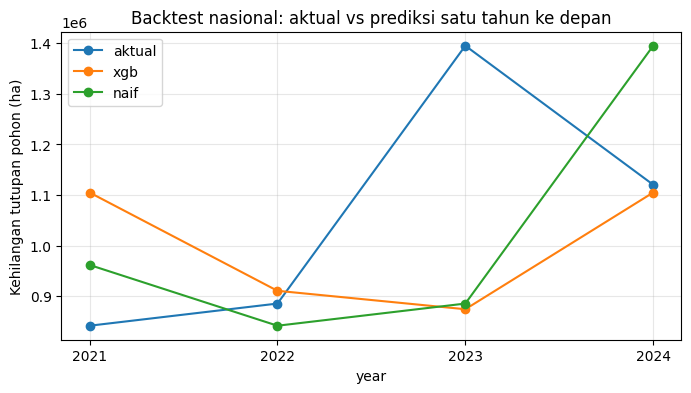

In [10]:
nat = bt.groupby("year").agg(aktual=("loss_ha", "sum"),
                             xgb=("pred_xgb", lambda s: np.expm1(s).sum()),
                             naif=("lag_1", lambda s: np.expm1(s).sum()))
ax = nat.plot(marker="o", figsize=(8, 4), title="Backtest nasional: aktual vs prediksi satu tahun ke depan")
ax.set_xticks(nat.index); ax.set_ylabel("Kehilangan tutupan pohon (ha)"); plt.grid(alpha=.3); plt.show()

## 8. Model final (dilatih ulang dengan semua data 2006-2024)

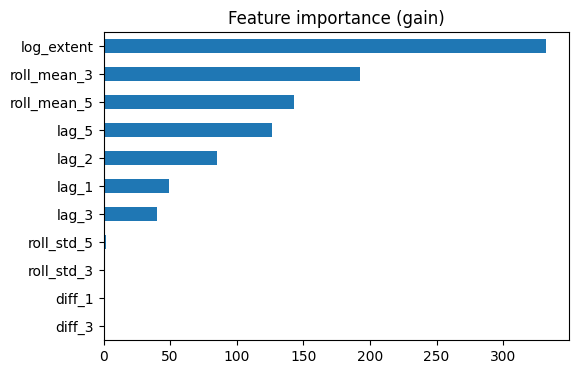

In [11]:
final_model = xgb.train(best_params, xgb.DMatrix(model_df[FEATURES], label=model_df["log_loss"]),
                        num_boost_round=n_rounds)
imp = pd.Series(final_model.get_score(importance_type="gain")).sort_values()
imp.plot.barh(figsize=(6, 4), title="Feature importance (gain)"); plt.show()

## 9. Prakiraan rekursif 2025-2030

Setiap langkah: prediksi tahun *t* ditambahkan ke deret, lalu **semua** fitur dihitung ulang dari deret itu untuk tahun *t+1*. Kesalahan menumpuk seiring horizon, jadi angka tahun-tahun akhir paling tidak pasti. Emisi prakiraan = kehilangan × faktor emisi per hektar provinsi (total emisi GFW ÷ total kehilangan, 2020-2024; provinsi tanpa data memakai faktor nasional).

In [12]:
def recursive_forecast(model, base, horizon):
    d = base[["subnational1", "year", "extent_2000_ha", "log_loss"]].copy()
    last = int(d["year"].max()); preds = []
    for step in range(1, horizon + 1):
        y = last + step
        nxt = d[d["year"] == y - 1][["subnational1", "extent_2000_ha"]].assign(year=y, log_loss=np.nan)
        d = pd.concat([d, nxt], ignore_index=True)
        f = make_features(d); row = f[f["year"] == y]
        p = dict(zip(row["subnational1"], model.predict(xgb.DMatrix(row[FEATURES]))))
        mask = d["year"] == y
        d.loc[mask, "log_loss"] = d.loc[mask, "subnational1"].map(p)
        preds.append(d[mask])
    out = pd.concat(preds)
    out["loss_ha"] = np.clip(np.expm1(out["log_loss"]), 0, None)
    return out

lo, hi = EMISSION_FACTOR_YEARS
w = hist[hist["year"].between(lo, hi)].groupby("subnational1")[["emission_CO2e", "loss_ha"]].sum()
national_factor = w["emission_CO2e"].sum() / w["loss_ha"].sum()
factor = (w["emission_CO2e"] / w["loss_ha"]).replace([np.inf, 0], np.nan).fillna(national_factor)
print(f"Faktor emisi nasional {lo}-{hi}: {national_factor:,.1f} Mg CO2e/ha")

fc = recursive_forecast(final_model, hist, FORECAST_HORIZON)
fc["loss_rate_%"] = fc["loss_ha"] / fc["extent_2000_ha"] * 100
fc["emission_CO2e"] = fc["loss_ha"] * fc["subnational1"].map(factor)
fc.groupby("year")[["loss_ha", "emission_CO2e"]].sum().round(0)

Faktor emisi nasional 2020-2024: 614.1 Mg CO2e/ha


,loss_ha,emission_CO2e
year,,
2025,1056214.0,651093822.0
2026,1042895.0,644020008.0
2027,1006438.0,622020368.0
2028,999527.0,619997630.0
2029,959564.0,594564274.0
2030,960248.0,595961676.0


## 10. Simpan keluaran untuk repo dan dashboard

In [13]:
COLS = ["subnational1", "year", "loss_ha", "loss_rate_%", "emission_CO2e", "source"]
full = pd.concat([hist.assign(source="historical")[COLS], fc.assign(source="forecast")[COLS]],
                 ignore_index=True).sort_values(["subnational1", "year"])
full.to_csv(f"{OUT_DATA}/deforestation_historical_forecast_full.csv", index=False)
hist[["subnational1", "year", "extent_2000_ha", "loss_ha", "loss_rate_%", "emission_CO2e"]] \
    .to_csv(f"{OUT_DATA}/history_ready.csv", index=False)
final_model.save_model(f"{OUT_MODEL}/xgb_model.json")
meta = {"features": FEATURES, "lags": LAGS, "windows": WINDOWS, "horizon": FORECAST_HORIZON,
        "threshold": THRESHOLD, "params": best_params, "n_rounds": n_rounds,
        "emission_factor_years": list(EMISSION_FACTOR_YEARS),
        "emission_factor_Mg_CO2e_per_ha": factor.to_dict(),
        "xgboost_version": xgb.__version__}
with open(f"{OUT_MODEL}/metadata.json", "w") as fh:
    json.dump(meta, fh, indent=2)
eval_table.to_csv(f"{OUT_DATA}/evaluation_split.csv"); bt_table.to_csv(f"{OUT_DATA}/evaluation_backtest.csv")
print(full["source"].value_counts().to_dict(), "| file tersimpan di outputs/")

{'historical': 816, 'forecast': 204} | file tersimpan di outputs/


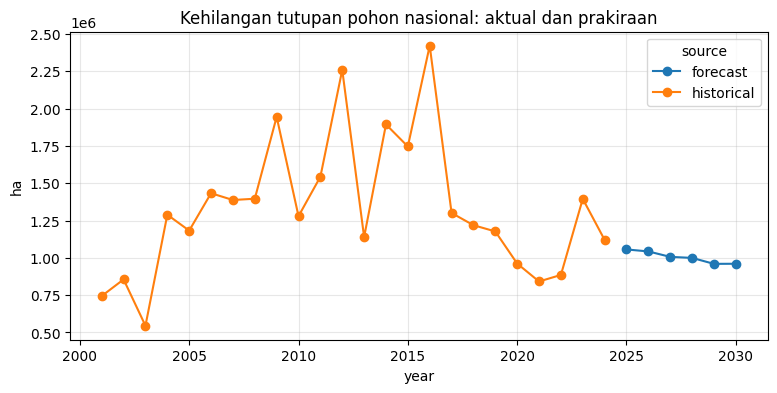

In [14]:
nat = full.groupby(["year", "source"])["loss_ha"].sum().unstack()
ax = nat.plot(marker="o", figsize=(9, 4), title="Kehilangan tutupan pohon nasional: aktual dan prakiraan")
ax.set_ylabel("ha"); plt.grid(alpha=.3); plt.show()

## 11. Keterbatasan

- *Tree cover loss* bukan deforestasi; termasuk rotasi perkebunan dan kebakaran.
- Hanya 34 deret pendek (2001-2024); fitur lag 5 membuat data latih mulai 2006.
- Hiperparameter dipilih pada 2021-2023; hanya 2024 yang benar-benar tak terlihat.
- Prakiraan rekursif tanpa interval ketidakpastian; kesalahan menumpuk tiap tahun.
- Faktor emisi diasumsikan tetap sama dengan rata-rata 2020-2024.
- Batas provinsi mengikuti data GFW (34 provinsi).

In [15]:
!zip -r deforestation_outputs.zip outputs

  adding: outputs/ (stored 0%)
  adding: outputs/data/ (stored 0%)
  adding: outputs/data/deforestation_historical_forecast_full.csv (deflated 67%)
  adding: outputs/data/history_ready.csv (deflated 61%)
  adding: outputs/data/evaluation_split.csv (deflated 45%)
  adding: outputs/data/evaluation_backtest.csv (deflated 26%)
  adding: outputs/model/ (stored 0%)
  adding: outputs/model/metadata.json (deflated 54%)
  adding: outputs/model/xgb_model.json (deflated 85%)
